In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('house_prices.csv')
df.head()

,Property_ID,Area,Bedrooms,Bathrooms,Age,Location,Property_Type,Price
0,PROP0001,3712,4,3,36,Rural,House,22260000
1,PROP0002,1591,4,1,35,Suburb,House,16057500
2,PROP0003,1646,4,3,20,Rural,Villa,12730000
3,PROP0004,4814,1,2,13,City Center,Villa,50840000
4,PROP0005,800,4,2,38,Suburb,Apartment,10650000


In [4]:
print(df.shape)
print(df.columns)
df.info()

(300, 8)
Index(['Property_ID', 'Area', 'Bedrooms', 'Bathrooms', 'Age', 'Location',
       'Property_Type', 'Price'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Property_ID    300 non-null    object
 1   Area           300 non-null    int64 
 2   Bedrooms       300 non-null    int64 
 3   Bathrooms      300 non-null    int64 
 4   Age            300 non-null    int64 
 5   Location       300 non-null    object
 6   Property_Type  300 non-null    object
 7   Price          300 non-null    int64 
dtypes: int64(5), object(3)
memory usage: 18.9+ KB


In [5]:
print(df.isnull().sum())

Property_ID      0
Area             0
Bedrooms         0
Bathrooms        0
Age              0
Location         0
Property_Type    0
Price            0
dtype: int64


In [6]:
print(df.duplicated().sum())

0


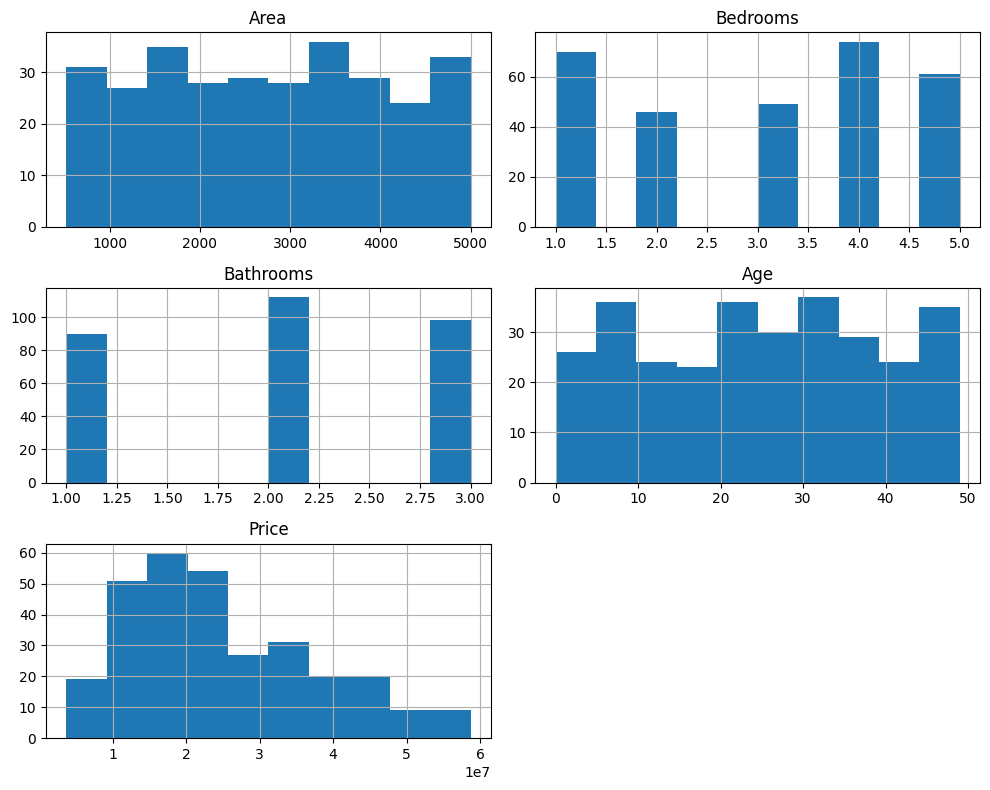

In [7]:
df.hist(figsize=(10, 8))
plt.tight_layout()
plt.show()

In [8]:
df.isnull().sum()

,0
Property_ID,0
Area,0
Bedrooms,0
Bathrooms,0
Age,0
Location,0
Property_Type,0
Price,0


In [9]:
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].median())

In [10]:
df.drop_duplicates(inplace=True)

In [12]:
print(df.columns.tolist())

['Property_ID', 'Area', 'Bedrooms', 'Bathrooms', 'Age', 'Location', 'Property_Type', 'Price']


In [14]:
X = df.drop('Price', axis=1)
y = df['Price']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (300, 7)
Target: (300,)


In [15]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (240, 307)
Testing Data: (60, 307)


In [17]:
print("Data Preparation Completed!")
print(X_train.head())

Data Preparation Completed!
     Area  Bedrooms  Bathrooms  Age  Property_ID_PROP0002  \
232  3511         5          2   45                     0   
59   3911         3          1   17                     0   
6    2705         1          3   13                     0   
185  3539         5          1   37                     0   
173   814         4          1   48                     0   

     Property_ID_PROP0003  Property_ID_PROP0004  Property_ID_PROP0005  \
232                     0                     0                     0   
59                      0                     0                     0   
6                       0                     0                     0   
185                     0                     0                     0   
173                     0                     0                     0   

     Property_ID_PROP0006  Property_ID_PROP0007  ...  Property_ID_PROP0295  \
232                     0                     0  ...                     0   
59        

In [18]:
X_area = df['Area']
y_price = df['Price']

mean_x = X_area.mean()
mean_y = y_price.mean()

print("Mean Area:", mean_x)
print("Mean Price:", mean_y)

Mean Area: 2759.7
Mean Price: 24883658.333333332


In [19]:
m = sum((X_area - mean_x) * (y_price - mean_y)) / sum((X_area - mean_x)**2)

c = mean_y - m * mean_x

print("Slope:", m)
print("Intercept:", c)

Slope: 7771.692409121677
Intercept: 3436118.7918802425


In [20]:
predicted_price = m * X_area + c

print(predicted_price.head())

0    3.228464e+07
1    1.580088e+07
2    1.622832e+07
3    4.084905e+07
4    9.653473e+06
Name: Area, dtype: float64


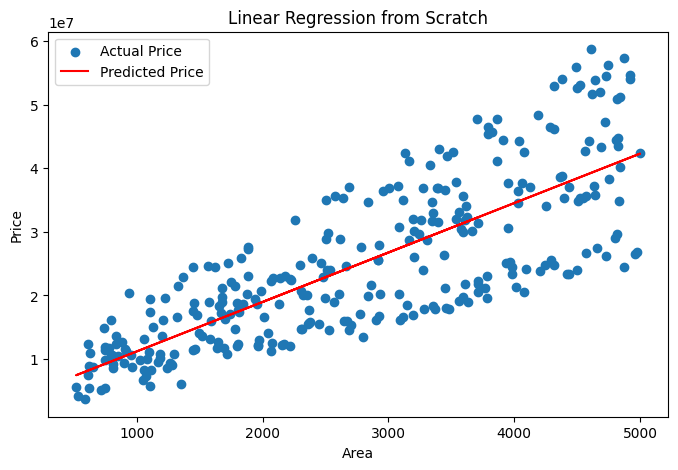

In [21]:
plt.figure(figsize=(8,5))

plt.scatter(X_area, y_price, label='Actual Price')
plt.plot(X_area, predicted_price, color='red', label='Predicted Price')

plt.xlabel('Area')
plt.ylabel('Price')
plt.title('Linear Regression from Scratch')

plt.legend()
plt.show()

In [22]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [23]:
model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [24]:
y_pred = model.predict(X_test)

print("Predicted Prices:")
print(y_pred[:10])

Predicted Prices:
[16027440.58835209 18916367.23625974 48016549.689415   27401189.53880021
 22207756.38956512 32637095.12898437 23347245.50953749 37995681.39570448
 28245191.46029613 30290566.72431821]


In [25]:
result = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

result.head(10)

,Actual Price,Predicted Price
0,8930000,1.602744e+07
1,18085000,1.891637e+07
2,53980000,4.801655e+07
3,24800000,2.740119e+07
4,21615000,2.220776e+07
5,31850000,3.263710e+07
6,18850000,2.334725e+07
7,41170000,3.799568e+07
8,24790000,2.824519e+07
9,30172500,3.029057e+07


In [26]:
print("Training Score:", model.score(X_train, y_train))
print("Testing Score:", model.score(X_test, y_test))

Training Score: 1.0
Testing Score: 0.9345471804672847


In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [29]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("R2 Score:", r2)

MAE: 2356914.287865374
MSE: 9321646434831.514
R2 Score: 0.9345471804672847


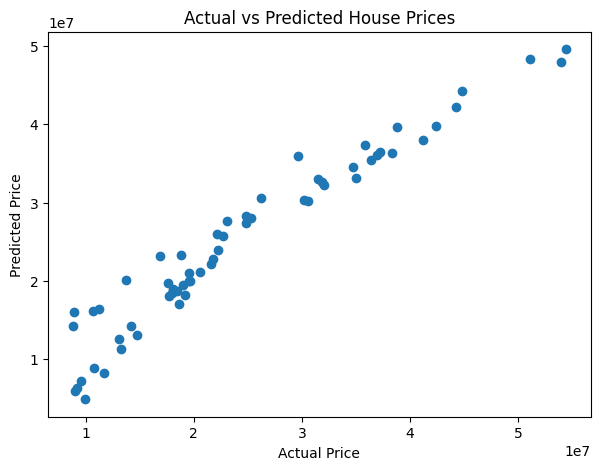

In [30]:
plt.figure(figsize=(7,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [32]:
print("HOUSE PRICE PREDICTION MODEL")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("R2 Score:", round(r2, 2))

HOUSE PRICE PREDICTION MODEL
MAE: 2356914.29
MSE: 9321646434831.51
R2 Score: 0.93


In [33]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [34]:
dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree R2:", r2_score(y_test, dt_pred))

Decision Tree R2: 0.9381645623313507


In [35]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest R2:", r2_score(y_test, rf_pred))

Random Forest R2: 0.9662933512297359


In [36]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest'],
    'R2 Score': [
        r2_score(y_test, y_pred),
        r2_score(y_test, dt_pred),
        r2_score(y_test, rf_pred)
    ]
})

results

,Model,R2 Score
0,Linear Regression,0.934547
1,Decision Tree,0.938165
2,Random Forest,0.966293


In [37]:
best_model = results.loc[results['R2 Score'].idxmax()]

print("Best Model:", best_model['Model'])
print("Best R2 Score:", best_model['R2 Score'])

Best Model: Random Forest
Best R2 Score: 0.9662933512297359


In [38]:
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance', ascending=False
)

print(importance)

                  Feature  Importance
0                    Area    0.690919
303        Location_Rural    0.201437
304       Location_Suburb    0.073057
1                Bedrooms    0.016718
3                     Age    0.006531
..                    ...         ...
242  Property_ID_PROP0240    0.000000
240  Property_ID_PROP0238    0.000000
12   Property_ID_PROP0010    0.000000
10   Property_ID_PROP0008    0.000000
8    Property_ID_PROP0006    0.000000

[307 rows x 2 columns]


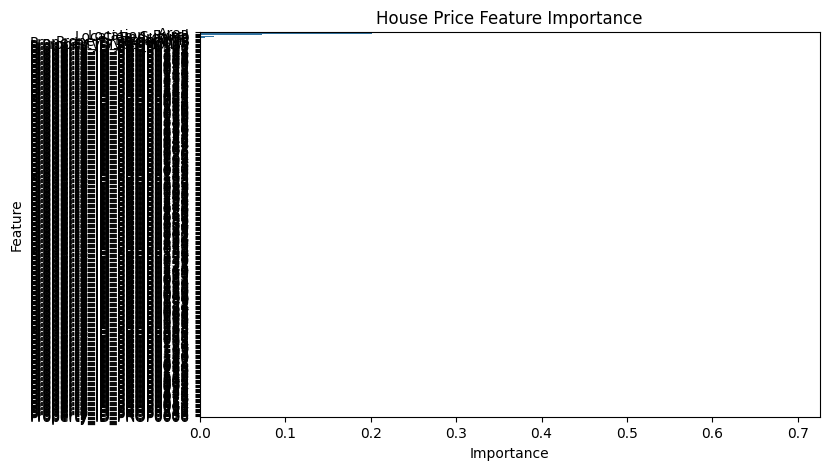

In [39]:
plt.figure(figsize=(8,5))

sns.barplot(data=importance, x='Importance', y='Feature')

plt.title('House Price Feature Importance')
plt.show()

In [40]:
print(results)

               Model  R2 Score
0  Linear Regression  0.934547
1      Decision Tree  0.938165
2      Random Forest  0.966293


In [41]:
best_model_name = results.loc[results['R2 Score'].idxmax(), 'Model']

if best_model_name == 'Linear Regression':
    final_pred = y_pred
elif best_model_name == 'Decision Tree':
    final_pred = dt_pred
else:
    final_pred = rf_pred

print("Best Model:", best_model_name)
print("MAE:", mean_absolute_error(y_test, final_pred))
print("MSE:", mean_squared_error(y_test, final_pred))
print("R2 Score:", r2_score(y_test, final_pred))

Best Model: Random Forest
MAE: 1623443.75
MSE: 4800426697927.083
R2 Score: 0.9662933512297359


In [42]:
import joblib

joblib.dump(model, 'house_price_model.pkl')

print("Model Saved Successfully!")

Model Saved Successfully!


# House Price Prediction Report

## 1. Project Overview
This project predicts house prices using Machine Learning.

## 2. Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

## 3. Models Used
- Linear Regression
- Decision Tree
- Random Forest

## 4. Evaluation Metrics
- MAE
- MSE
- R2 Score

## 5. Results
Best Model: Add your best model name.

MAE: Add your result.

MSE: Add your result.

R2 Score: Add your result.

## 6. Conclusion
The project successfully predicts house prices.
Area, Bedrooms and Location help explain
house price variations.

In [43]:
report = """
# House Price Prediction – Model Evaluation Report

## 1. Project Overview
This project predicts house prices using Machine Learning.

## 2. Dataset
- Dataset: house_prices.csv
- Rows: 300
- Target: Price

## 3. Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

## 4. Models Used
- Linear Regression
- Decision Tree
- Random Forest

## 5. Evaluation Metrics
- MAE
- MSE
- R2 Score

## 6. Results
Add your actual model results here.

## 7. Conclusion
This project predicts house prices using Machine Learning.
"""

with open("model_evaluation_report.md", "w") as file:
    file.write(report)

print("Report saved successfully!")

Report saved successfully!


In [44]:
from google.colab import files

files.download("model_evaluation_report.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:
requirements = """
pandas
numpy
matplotlib
seaborn
scikit-learn
joblib
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [46]:
from google.colab import files

files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>